---
title: "Customers Clustering"
description: " "
date: 2023-06-19
categories: [Machine Learning, Clustering]
image: images/marketing-campaign.jpg
---

<ol class="breadcrumb">
  <li class="breadcrumb-item"><a href="../../index.qmd">Home</a></li>
  <li class="breadcrumb-item"><a href="../ai/index.qmd">Artificial Intelligence Projects</a></li>
  <li class="breadcrumb-item active">Customers Clustering</li>
</ol>

## Overview

This notebook applies unsupervised machine learning to customer segmentation by identifying groups of customers with similar purchasing characteristics within the following dataset.

[<i class="bi bi-download"></i> Download Dataset (.csv)](data/marketing_campaign.csv){.btn .btn-secondary role="button" download="" target="_blank}

The analysis explores customer behavior through these main steps:

1. Data preprocessing and Exploratory Data Analysis (EDA)
2. Model training
3. Model evaluation

The analysis focuses on understanding the underlying structure of the data, applying K-Means clustering algorithm, and evaluating the resulting clusters to assess their quality and interpretability.

## Install and Import Packages

In [ ]:
%pip install --upgrade -q matplotlib pandas scikit-learn seaborn

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## Load Dataset

In [3]:
df = pd.read_csv('data/marketing_campaign.csv', delimiter='\t')
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,0,0,0,0,0,0,3,11,0


**Dataset Description**

Columns/Features:

- ID: id

- Year_Birth: customer's year birth

- Education: customer’s level of education

- Marital_Status: customer’s marital status

- Income: customer’s yearly household income

- Kidhome: number of small children in customer’s household

- Teenhome: number of teenagers in customer’s household

- DtCustomer: date of customer’s enrolment with the company

- Recency: number of days since the last purchase

- MntWines: amount spent on wine products in the last 2 years

- MntFruits: amount spent on fruits products in the last 2 years

- MntMeatProducts: amount spent on meat products in the last 2 years

- MntFishProducts: amount spent on fish products in the last 2 years

- MntSweetProducts: amount spent on sweet products in the last 2 years

- MntGoldProds: amount spent on gold products in the last 2 years

- AcceptedCmp1: 1 if customer accepted the offer in the 1st campaign, 0 otherwise

- AcceptedCmp2: 1 if customer accepted the offer in the 2nd campaign, 0 otherwise

- AcceptedCmp3: 1 if customer accepted the offer in the 3rd campaign, 0 otherwise

- AcceptedCmp4: 1 if customer accepted the offer in the 4th campaign, 0 otherwise

- AcceptedCmp5: 1 if customer accepted the offer in the 5th campaign, 0 otherwise

- NumDealsPurchases: number of purchases made with discount

- NumWebPurchases: number of purchases made through company’s web site

- NumCatalogPurchases: number of purchases made using catalogue

- NumStorePurchase:- number of purchases made directly in stores

- NumWebVisitsMonth: number of visits to company’s web site in the last month

- Complain: 1 if customer complained in the last 2 years

- Response (target): 1 if customer accepted the offer in the last campaign, 0 otherwise

**Acknowledgements**

O. Parr-Rud. Business Analytics Using SAS Enterprise Guide and SAS Enterprise Miner. SAS Institute, 2014.

## Data Preprocessing and EDA 

First, let's take a look at the datasets overview.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

Based on the output above, here are some informations about the dataset.
- The dataset has 2240 rows and 29 columns.
- There is a feature with missing values. 
- The features consist of both numerical and categorical features, also a date data.

Also, based on the dataset description, the dataset was meant to build a classification model for response variable. However, in this assignment, we are going to do a clustering, an unsupervised learning which doesn't need label or target variable. So, the **Response column need to be dropped** prior to clustering because it represents the target label for supervised tasks. Since clustering is an unsupervised technique aimed at discovering natural patterns within customer demographics and behaviors, including the target variable would introduce label leakage and bias the cluster formation.

There are also some features that are not described in the dataset description: **Z_CostContact** and **Z_Revenue**. Let's see those features.

In [5]:
df['Z_CostContact'].value_counts()

Z_CostContact
3    2240
Name: count, dtype: int64

In [6]:
df['Z_Revenue'].value_counts()

Z_Revenue
11    2240
Name: count, dtype: int64

Notice that they are having only one value for all rows. This means they don't have important information just like column **ID**. So, we also need to drop **ID**, **Z_CostContact**, and **Z_Revenue**.

### Drop Unnecessary Columns

In [7]:
df = df.drop(columns=['ID', 'Z_CostContact', 'Z_Revenue', 'Response'])
df

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain
0,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,...,8,10,4,7,0,0,0,0,0,0
1,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,...,1,1,2,5,0,0,0,0,0,0
2,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,...,8,2,10,4,0,0,0,0,0,0
3,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,...,2,0,4,6,0,0,0,0,0,0
4,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,...,5,3,6,5,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,43,...,9,3,4,5,0,0,0,0,0,0
2236,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,0,...,8,2,5,7,0,0,0,1,0,0
2237,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,48,...,2,3,13,6,0,1,0,0,0,0
2238,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,30,...,6,5,10,3,0,0,0,0,0,0


#### Checking dan Dropping Duplicated Rows

In [8]:
# check and drop duplicated rows (if exist)
total_duplicates = df.duplicated().sum()
print(f'Total duplicated rows: {total_duplicates}')
if total_duplicates:
    df = df.drop_duplicates().reset_index(drop=True)
    print('All duplicated rows has been removed.')
else:
    print('No duplicated rows need to be dropped.')

Total duplicated rows: 201
All duplicated rows has been removed.


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2039 entries, 0 to 2038
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year_Birth           2039 non-null   int64  
 1   Education            2039 non-null   str    
 2   Marital_Status       2039 non-null   str    
 3   Income               2015 non-null   float64
 4   Kidhome              2039 non-null   int64  
 5   Teenhome             2039 non-null   int64  
 6   Dt_Customer          2039 non-null   str    
 7   Recency              2039 non-null   int64  
 8   MntWines             2039 non-null   int64  
 9   MntFruits            2039 non-null   int64  
 10  MntMeatProducts      2039 non-null   int64  
 11  MntFishProducts      2039 non-null   int64  
 12  MntSweetProducts     2039 non-null   int64  
 13  MntGoldProds         2039 non-null   int64  
 14  NumDealsPurchases    2039 non-null   int64  
 15  NumWebPurchases      2039 non-null   int64  
 16 

### Handling Missing Values

Remember that the dataset has missing values.

In [10]:
df.isna().sum()

Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
dtype: int64

The only feature that has missing values is **Income**. Let's handle this using imputation by median to mitigate the influence of extreme values.

In [11]:
df['Income'] = df['Income'].fillna(df['Income'].median())

In [12]:
df.isna().sum()

Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
dtype: int64

### Feature Engineering

Raw birth years (e.g., 1970, 1985) serve as temporal identifiers rather than meaningful numerical distances for distance-based clustering algorithms like K-Means. To make this information actionable, Year_Birth was converted into a continuous Age feature calculated relative to the dataset’s collection period (2014):

$$\text{Age} = 2014 - \text{Year\_Birth}$$

Converting birth years into age provides a standardized continuous variable that intuitively reflects customer life stages and demographic profiles, making it suitable for feature scaling and interpretation.

Then, the distance-based algorithms (K-Means) cannot directly interpret datetime formats or string-based date stamps. Furthermore, specific join dates lack context regarding customer loyalty. To extract functional value, Dt_Customer was transformed into Customer_Tenure_Days, measuring the total number of days a customer has been registered relative to the end of the data collection window (December 31, 2014):

$$\text{Membership\_Duration\_Day} = \text{Reference Date (31-12-2014)} - \text{Dt\_Customer}$$

This conversion creates a continuous metric representing customer loyalty and tenure duration, allowing algorithms to compute meaningful Euclidean distances between long-term and newly acquired customers.

In [13]:
feat_eng_df = df.copy()

feat_eng_df['Year_Birth'] = feat_eng_df['Year_Birth'].apply(lambda x: 2014 - x)

feat_eng_df['Dt_Customer'] = pd.to_datetime(feat_eng_df['Dt_Customer'], format='%d-%m-%Y')
feat_eng_df['Dt_Customer'] = (pd.to_datetime('31-12-2014', format='%d-%m-%Y') - feat_eng_df['Dt_Customer']).dt.days

feat_eng_df = feat_eng_df.rename(columns={'Year_Birth': 'Age', 'Dt_Customer': 'Membership_Duration_Day'})

In [14]:
feat_eng_df.head()

,Age,Education,Marital_Status,Income,Kidhome,Teenhome,Membership_Duration_Day,Recency,MntWines,MntFruits,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain
0,57,Graduation,Single,58138.0,0,0,848,58,635,88,...,8,10,4,7,0,0,0,0,0,0
1,60,Graduation,Single,46344.0,1,1,298,38,11,1,...,1,1,2,5,0,0,0,0,0,0
2,49,Graduation,Together,71613.0,0,0,497,26,426,49,...,8,2,10,4,0,0,0,0,0,0
3,30,Graduation,Together,26646.0,1,0,324,26,11,4,...,2,0,4,6,0,0,0,0,0,0
4,33,PhD,Married,58293.0,1,0,346,94,173,43,...,5,3,6,5,0,0,0,0,0,0


The dataset contains five individual binary indicators (AcceptedCmp1 through AcceptedCmp5) representing historical campaign acceptances. Keeping these as separate binary columns creates high sparsity and adds unhelpful dimensionality to distance metrics. To capture overall engagement without distorting cluster distances, these binary columns were aggregated into a single continuous feature:

$$\text{Total\_Accepted\_Cmp} = \sum_{i=1}^{5} \text{AcceptedCmp}_i$$

Aggregating these columns summarizes a customer's overall responsiveness to marketing promotions into a single metric. This reduces dimensionality, eliminates sparse binary redundancy, and provides a clearer indication of promotional sensitivity across different customer segments.

In [15]:
feat_eng_df['Total_AcceptedCmp'] = (feat_eng_df['AcceptedCmp1'] + feat_eng_df['AcceptedCmp2'] + feat_eng_df['AcceptedCmp3']
                                    + feat_eng_df['AcceptedCmp4'] + feat_eng_df['AcceptedCmp5'])
feat_eng_df = feat_eng_df.drop(columns=['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5'])

In [16]:
feat_eng_df.head()

,Age,Education,Marital_Status,Income,Kidhome,Teenhome,Membership_Duration_Day,Recency,MntWines,MntFruits,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Total_AcceptedCmp
0,57,Graduation,Single,58138.0,0,0,848,58,635,88,...,172,88,88,3,8,10,4,7,0,0
1,60,Graduation,Single,46344.0,1,1,298,38,11,1,...,2,1,6,2,1,1,2,5,0,0
2,49,Graduation,Together,71613.0,0,0,497,26,426,49,...,111,21,42,1,8,2,10,4,0,0
3,30,Graduation,Together,26646.0,1,0,324,26,11,4,...,10,3,5,2,2,0,4,6,0,0
4,33,PhD,Married,58293.0,1,0,346,94,173,43,...,46,27,15,5,5,3,6,5,0,0


Now, let's separate the dataframe into 2 parts: numerical features only and categorical features only.

In [17]:
cat_columns = ['Education', 'Marital_Status', 'Complain']
num_columns = list(set(feat_eng_df.columns) - set(cat_columns))

cat_df = feat_eng_df[cat_columns]
num_df = feat_eng_df[num_columns]

In [18]:
cat_df

,Education,Marital_Status,Complain
0,Graduation,Single,0
1,Graduation,Single,0
2,Graduation,Together,0
3,Graduation,Together,0
4,PhD,Married,0
...,...,...,...
2034,Graduation,Together,0
2035,Graduation,Married,0
2036,Graduation,Divorced,0
2037,Master,Together,0


In [19]:
num_df

,Total_AcceptedCmp,Income,MntSweetProducts,NumWebPurchases,Kidhome,Age,NumCatalogPurchases,Teenhome,MntFishProducts,MntFruits,Recency,MntWines,NumStorePurchases,NumWebVisitsMonth,MntMeatProducts,Membership_Duration_Day,NumDealsPurchases,MntGoldProds
0,0,58138.0,88,8,0,57,10,0,172,88,58,635,4,7,546,848,3,88
1,0,46344.0,1,1,1,60,1,1,2,1,38,11,2,5,6,298,2,6
2,0,71613.0,21,8,0,49,2,0,111,49,26,426,10,4,127,497,1,42
3,0,26646.0,3,2,1,30,0,0,10,4,26,11,4,6,20,324,2,5
4,0,58293.0,27,5,1,33,3,0,46,43,94,173,6,5,118,346,5,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2034,0,666666.0,1,3,1,37,1,0,8,14,23,9,3,6,18,577,4,12
2035,0,61223.0,118,9,0,47,3,1,42,43,46,709,4,5,182,566,2,247
2036,1,56981.0,12,2,0,33,3,0,32,48,91,908,13,6,217,340,1,24
2037,0,69245.0,30,6,0,58,5,1,80,30,8,428,10,3,214,341,2,61


### Scaling Numerical Features

Based on the displayed num_df, we can see that the numerical features exhibit vastly different scales and measurement ranges. StandardScaler is applied to transform all numerical features to possess a mean of 0 and a standard deviation of 1 ($\mu = 0, \sigma = 1$).

In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
num = num_df.values
num_scaled = scaler.fit_transform(num)
num_scaled_df = pd.DataFrame(num_scaled, columns=num_columns)

In [21]:
num_scaled_df

,Total_AcceptedCmp,Income,MntSweetProducts,NumWebPurchases,Kidhome,Age,NumCatalogPurchases,Teenhome,MntFishProducts,MntFruits,Recency,MntWines,NumStorePurchases,NumWebVisitsMonth,MntMeatProducts,Membership_Duration_Day,NumDealsPurchases,MntGoldProds
0,-0.440728,0.227572,1.457954,1.393739,-0.827258,0.982294,2.500739,-0.928320,2.460044,1.548411,0.307359,0.987869,-0.547717,0.693037,1.659882,1.541257,0.346961,0.850571
1,-0.440728,-0.236329,-0.628805,-1.106932,1.032476,1.232708,-0.565001,0.900515,-0.648302,-0.636735,-0.383073,-0.870707,-1.165755,-0.127342,-0.709844,-1.183111,-0.170183,-0.725991
2,-0.440728,0.757593,-0.149090,1.393739,-0.827258,0.314522,-0.224363,-0.928320,1.344696,0.568863,-0.797331,0.365365,1.306397,-0.537531,-0.178850,-0.197385,-0.687328,-0.033842
3,-0.440728,-1.011123,-0.580834,-0.749693,1.032476,-1.271435,-0.905639,-0.928320,-0.502027,-0.561386,-0.797331,-0.870707,-0.547717,0.282848,-0.648406,-1.054323,-0.170183,-0.745217
4,-0.440728,0.233669,-0.005176,0.322023,1.032476,-1.021021,0.116275,-0.928320,0.156211,0.418163,1.550135,-0.388192,0.070321,-0.127342,-0.218345,-0.945348,1.381250,-0.552953
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2034,-0.440728,24.163198,-0.628805,-0.392454,1.032476,-0.687135,-0.565001,-0.928320,-0.538596,-0.310219,-0.900896,-0.876664,-0.856736,0.282848,-0.657183,0.198887,0.864106,-0.610633
2035,-0.440728,0.348917,2.177526,1.750978,-0.827258,0.147579,0.116275,0.900515,0.083073,0.418163,-0.106900,1.208277,-0.547717,-0.127342,0.062511,0.144399,-0.170183,3.907562
2036,1.032460,0.182063,-0.364962,-0.749693,-0.827258,-1.021021,0.116275,-0.928320,-0.099771,0.543746,1.446570,1.800996,2.233454,0.282848,0.216105,-0.975069,-0.687328,-0.379916
2037,-0.440728,0.664451,0.066781,0.679262,-0.827258,1.065765,0.797550,0.900515,0.777880,0.091647,-1.418719,0.371322,1.306397,-0.947721,0.202939,-0.970115,-0.170183,0.331459


### Encoding Categorical Features

Note that machine learning algorithms can only process number. This means we need to encode the categorical features.

In [22]:
cat_df.head()

,Education,Marital_Status,Complain
0,Graduation,Single,0
1,Graduation,Single,0
2,Graduation,Together,0
3,Graduation,Together,0
4,PhD,Married,0


Before that, separate the categorical features only dataframe into 3 parts: ordinal categorical features that need encoding, nominal categorical features that need encoding, and categorical features that has already encoded. 

In [23]:
ord_cat_columns = ['Education']
nom_cat_columns = ['Marital_Status']

ord_cat_df = cat_df[ord_cat_columns]
nom_cat_df = cat_df[nom_cat_columns]
alr_encoded_cat_df = cat_df.drop(columns=ord_cat_columns + nom_cat_columns)

In [24]:
alr_encoded_cat_df

,Complain
0,0
1,0
2,0
3,0
4,0
...,...
2034,0
2035,0
2036,0
2037,0


#### Ordinal Encoding

Let's see the ordinal category

In [25]:
ord_cat_df.head()

,Education
0,Graduation
1,Graduation
2,Graduation
3,Graduation
4,PhD


In [26]:
ord_cat_df.value_counts()

Education 
Graduation    1025
PhD            442
Master         337
2n Cycle       186
Basic           49
Name: count, dtype: int64

In [27]:
# create ordinal mapping
education_mapping = {'Basic': 1, '2n Cycle': 2, 'Graduation': 3, 'Master': 4, 'PhD': 5}
ord_cat_df['Education'] = ord_cat_df['Education'].map(education_mapping)
ord_cat_df

,Education
0,3
1,3
2,3
3,3
4,5
...,...
2034,3
2035,3
2036,3
2037,4


#### One-Hot Encoding

In [28]:
nom_cat_encoded_df = pd.get_dummies(nom_cat_df, columns=nom_cat_df.columns, drop_first=True, dtype=int)
nom_cat_encoded_df

,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,0,0,0,1,0,0,0
1,0,0,0,1,0,0,0
2,0,0,0,0,1,0,0
3,0,0,0,0,1,0,0
4,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...
2034,0,0,0,0,1,0,0
2035,0,0,1,0,0,0,0
2036,0,1,0,0,0,0,0
2037,0,0,0,0,1,0,0


In [29]:
# concat all the preprocessed dataframes
df_preprocessed = pd.concat([num_scaled_df, alr_encoded_cat_df, ord_cat_df, nom_cat_encoded_df], axis=1).sort_index(axis=1)
df_preprocessed.head()

,Age,Complain,Education,Income,Kidhome,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,...,MntSweetProducts,MntWines,NumCatalogPurchases,NumDealsPurchases,NumStorePurchases,NumWebPurchases,NumWebVisitsMonth,Recency,Teenhome,Total_AcceptedCmp
0,0.982294,0,3,0.227572,-0.827258,0,0,0,1,0,...,1.457954,0.987869,2.500739,0.346961,-0.547717,1.393739,0.693037,0.307359,-0.928320,-0.440728
1,1.232708,0,3,-0.236329,1.032476,0,0,0,1,0,...,-0.628805,-0.870707,-0.565001,-0.170183,-1.165755,-1.106932,-0.127342,-0.383073,0.900515,-0.440728
2,0.314522,0,3,0.757593,-0.827258,0,0,0,0,1,...,-0.149090,0.365365,-0.224363,-0.687328,1.306397,1.393739,-0.537531,-0.797331,-0.928320,-0.440728
3,-1.271435,0,3,-1.011123,1.032476,0,0,0,0,1,...,-0.580834,-0.870707,-0.905639,-0.170183,-0.547717,-0.749693,0.282848,-0.797331,-0.928320,-0.440728
4,-1.021021,0,5,0.233669,1.032476,0,0,1,0,0,...,-0.005176,-0.388192,0.116275,1.381250,0.070321,0.322023,-0.127342,1.550135,-0.928320,-0.440728


## Train Model

In [30]:
X = df_preprocessed.values

### Find The Best K

To find the best k, we can use elbow method.

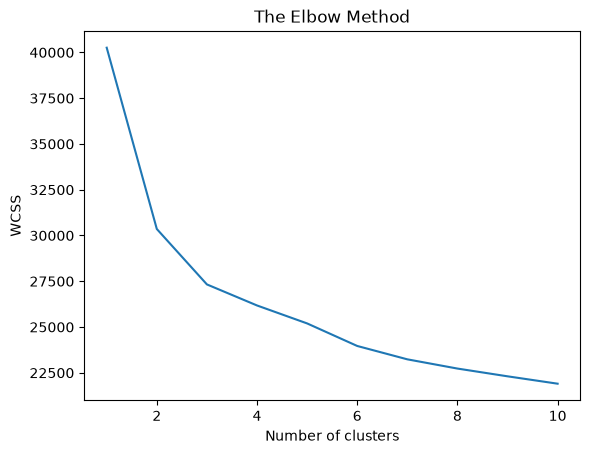

In [31]:
from sklearn.cluster import KMeans

# Using the elbow method to find the optimal number of clusters
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

From the elbow plot above, the elbow curve is relatively smooth. Identifying the "elbow" kind of somewhat subjective—choosing between $k=2$ and $k=3$. To determine this objectively, let's try another method which is silhouette score.

In [32]:
from sklearn.metrics import silhouette_score

scores = []
for i in range(2,11):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 42)
    kmeans.fit(X)
    labels = kmeans.labels_
    score = silhouette_score(X, labels)
    if scores:
        last_score = scores[-1]
        print (f'k = {i} | Silhouette score: {silhouette_score(X, labels):.4f} | Change from previous score: {(score - last_score):.4f}')
    else:
        print (f'k = {i} | Silhouette score: {silhouette_score(X, labels):.4f} | Change from previous score: -')
    scores.append(score)
    

k = 2 | Silhouette score: 0.2508 | Change from previous score: -
k = 3 | Silhouette score: 0.1825 | Change from previous score: -0.0683
k = 4 | Silhouette score: 0.1755 | Change from previous score: -0.0071
k = 5 | Silhouette score: 0.1544 | Change from previous score: -0.0210
k = 6 | Silhouette score: 0.1126 | Change from previous score: -0.0418
k = 7 | Silhouette score: 0.1101 | Change from previous score: -0.0025
k = 8 | Silhouette score: 0.1046 | Change from previous score: -0.0055
k = 9 | Silhouette score: 0.0901 | Change from previous score: -0.0144
k = 10 | Silhouette score: 0.0883 | Change from previous score: -0.0018


Based on the silhouette scores, **the best value for k is k = 3**. 

It is because k = 3 gives the highest score reduction from the previous silhouette score.

### Apply The Best K

In [33]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42)
kmeans.fit(X)

labels = kmeans.labels_
print(labels)

[2 1 2 ... 2 0 1]


## Model Evaluation

In [34]:
print(f'Intertia: {kmeans.inertia_}')

Intertia: 27326.500366475124


The final K-Means model with $k=3$ achieved an Inertia (Within-Cluster Sum of Squares) of 27326. This value represents the total squared distance of samples to their assigned cluster centers, reflecting the compactness of the formed clusters relative to the scaled feature space.

## Save Results

In [35]:
feat_eng_df = feat_eng_df.sort_index(axis=1)
feat_eng_df['label'] = labels
feat_eng_df

,Age,Education,Marital_Status,Income,Kidhome,Teenhome,Membership_Duration_Day,Recency,MntWines,MntFruits,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Total_AcceptedCmp,label
0,57,Graduation,Single,58138.0,0,0,848,58,635,88,...,88,88,3,8,10,4,7,0,0,2
1,60,Graduation,Single,46344.0,1,1,298,38,11,1,...,1,6,2,1,1,2,5,0,0,1
2,49,Graduation,Together,71613.0,0,0,497,26,426,49,...,21,42,1,8,2,10,4,0,0,2
3,30,Graduation,Together,26646.0,1,0,324,26,11,4,...,3,5,2,2,0,4,6,0,0,1
4,33,PhD,Married,58293.0,1,0,346,94,173,43,...,27,15,5,5,3,6,5,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2034,37,Graduation,Together,666666.0,1,0,577,23,9,14,...,1,12,4,3,1,3,6,0,0,2
2035,47,Graduation,Married,61223.0,0,1,566,46,709,43,...,118,247,2,9,3,4,5,0,0,0
2036,33,Graduation,Divorced,56981.0,0,0,340,91,908,48,...,12,24,1,2,3,13,6,0,1,2
2037,58,Master,Together,69245.0,0,1,341,8,428,30,...,30,61,2,6,5,10,3,0,0,0


## Results Visualization

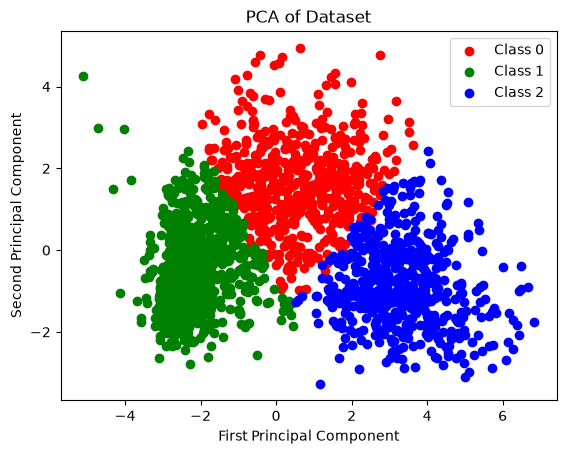

In [36]:
# visualize using PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_transformed = pca.fit_transform(X)

X_x = X_transformed[:, 0]
X_y = X_transformed[:, 1]

pca_df = pd.DataFrame({'X_x': X_x, 'X_y': X_y, 'label': labels})

plt.scatter(pca_df[pca_df['label']==0]['X_x'], pca_df[pca_df['label']==0]['X_y'], c='red', label='Class 0')
plt.scatter(pca_df[pca_df['label']==1]['X_x'], pca_df[pca_df['label']==1]['X_y'], c='green', label='Class 1')
plt.scatter(pca_df[pca_df['label']==2]['X_x'], pca_df[pca_df['label']==2]['X_y'], c='blue', label='Class 2')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA of Dataset')
plt.legend()
plt.show()

In [37]:
feat_eng_df['label'].value_counts()

label
1    947
0    558
2    534
Name: count, dtype: int64

## Clusters Interpretation

### Class 0

In [38]:
class_0_df = feat_eng_df[feat_eng_df['label'] == 0]
class_0_df.head()

,Age,Education,Marital_Status,Income,Kidhome,Teenhome,Membership_Duration_Day,Recency,MntWines,MntFruits,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Total_AcceptedCmp,label
5,47,Master,Together,62513.0,0,1,478,16,520,42,...,42,14,2,6,4,10,6,0,0,0
6,43,Graduation,Divorced,55635.0,0,1,778,34,235,65,...,49,27,4,7,3,7,6,0,0,0
13,62,Master,Divorced,59354.0,1,1,411,53,233,2,...,5,14,3,6,1,5,6,0,0,0
17,68,Graduation,Together,37760.0,0,0,852,20,84,5,...,12,28,2,4,1,6,7,0,0,0
18,65,Master,Married,76995.0,0,1,643,91,1012,80,...,16,176,2,11,4,9,5,0,1,0


In [51]:
def count_plot_class(df, cat_columns, target):
    countplot_df = df.copy()
    countplot_df = countplot_df[cat_columns]
    countplot_df[target] = df[target]

    n_columns = 3
    n_rows = (len(cat_columns) + n_columns - 1) // n_columns

    fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 5 * n_rows))
    axes = axes.flatten()

    for i, column in enumerate(cat_columns):
        sns.countplot(data=countplot_df, x=target, hue=column, ax=axes[i])

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.show()

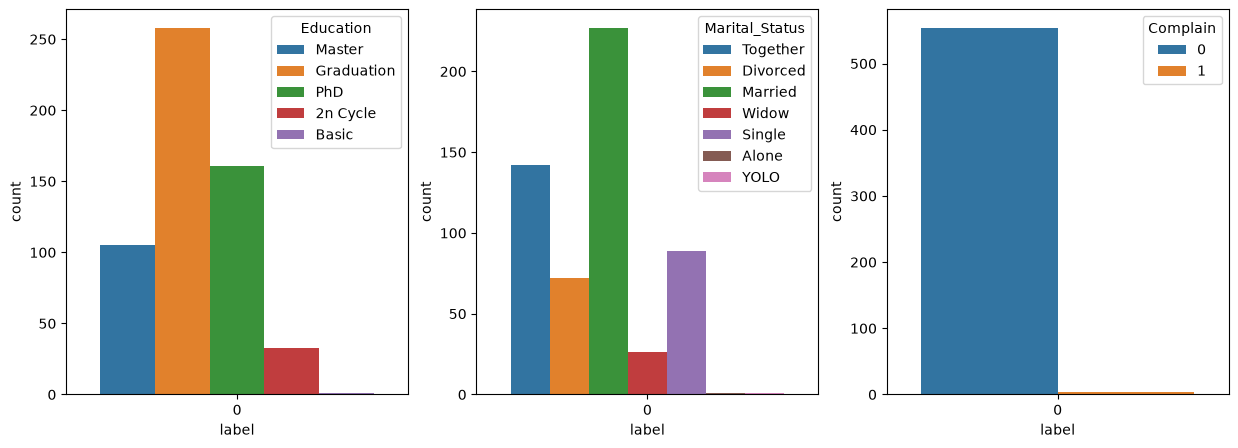

In [52]:
target = 'label'

count_plot_class(class_0_df, cat_columns, target)

In [55]:
def hist_plot_class(df, num_columns, target):
    histplot_df = df.copy()
    histplot_df = histplot_df[num_columns]
    histplot_df[target] = df[target]

    n_columns = 3
    n_rows = (len(num_columns) + n_columns - 1) // n_columns

    fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 5 * n_rows))
    axes = axes.flatten()

    for i, column in enumerate(num_columns):
        sns.histplot(data=histplot_df[column], kde=True, color='teal', ax=axes[i])

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.show()

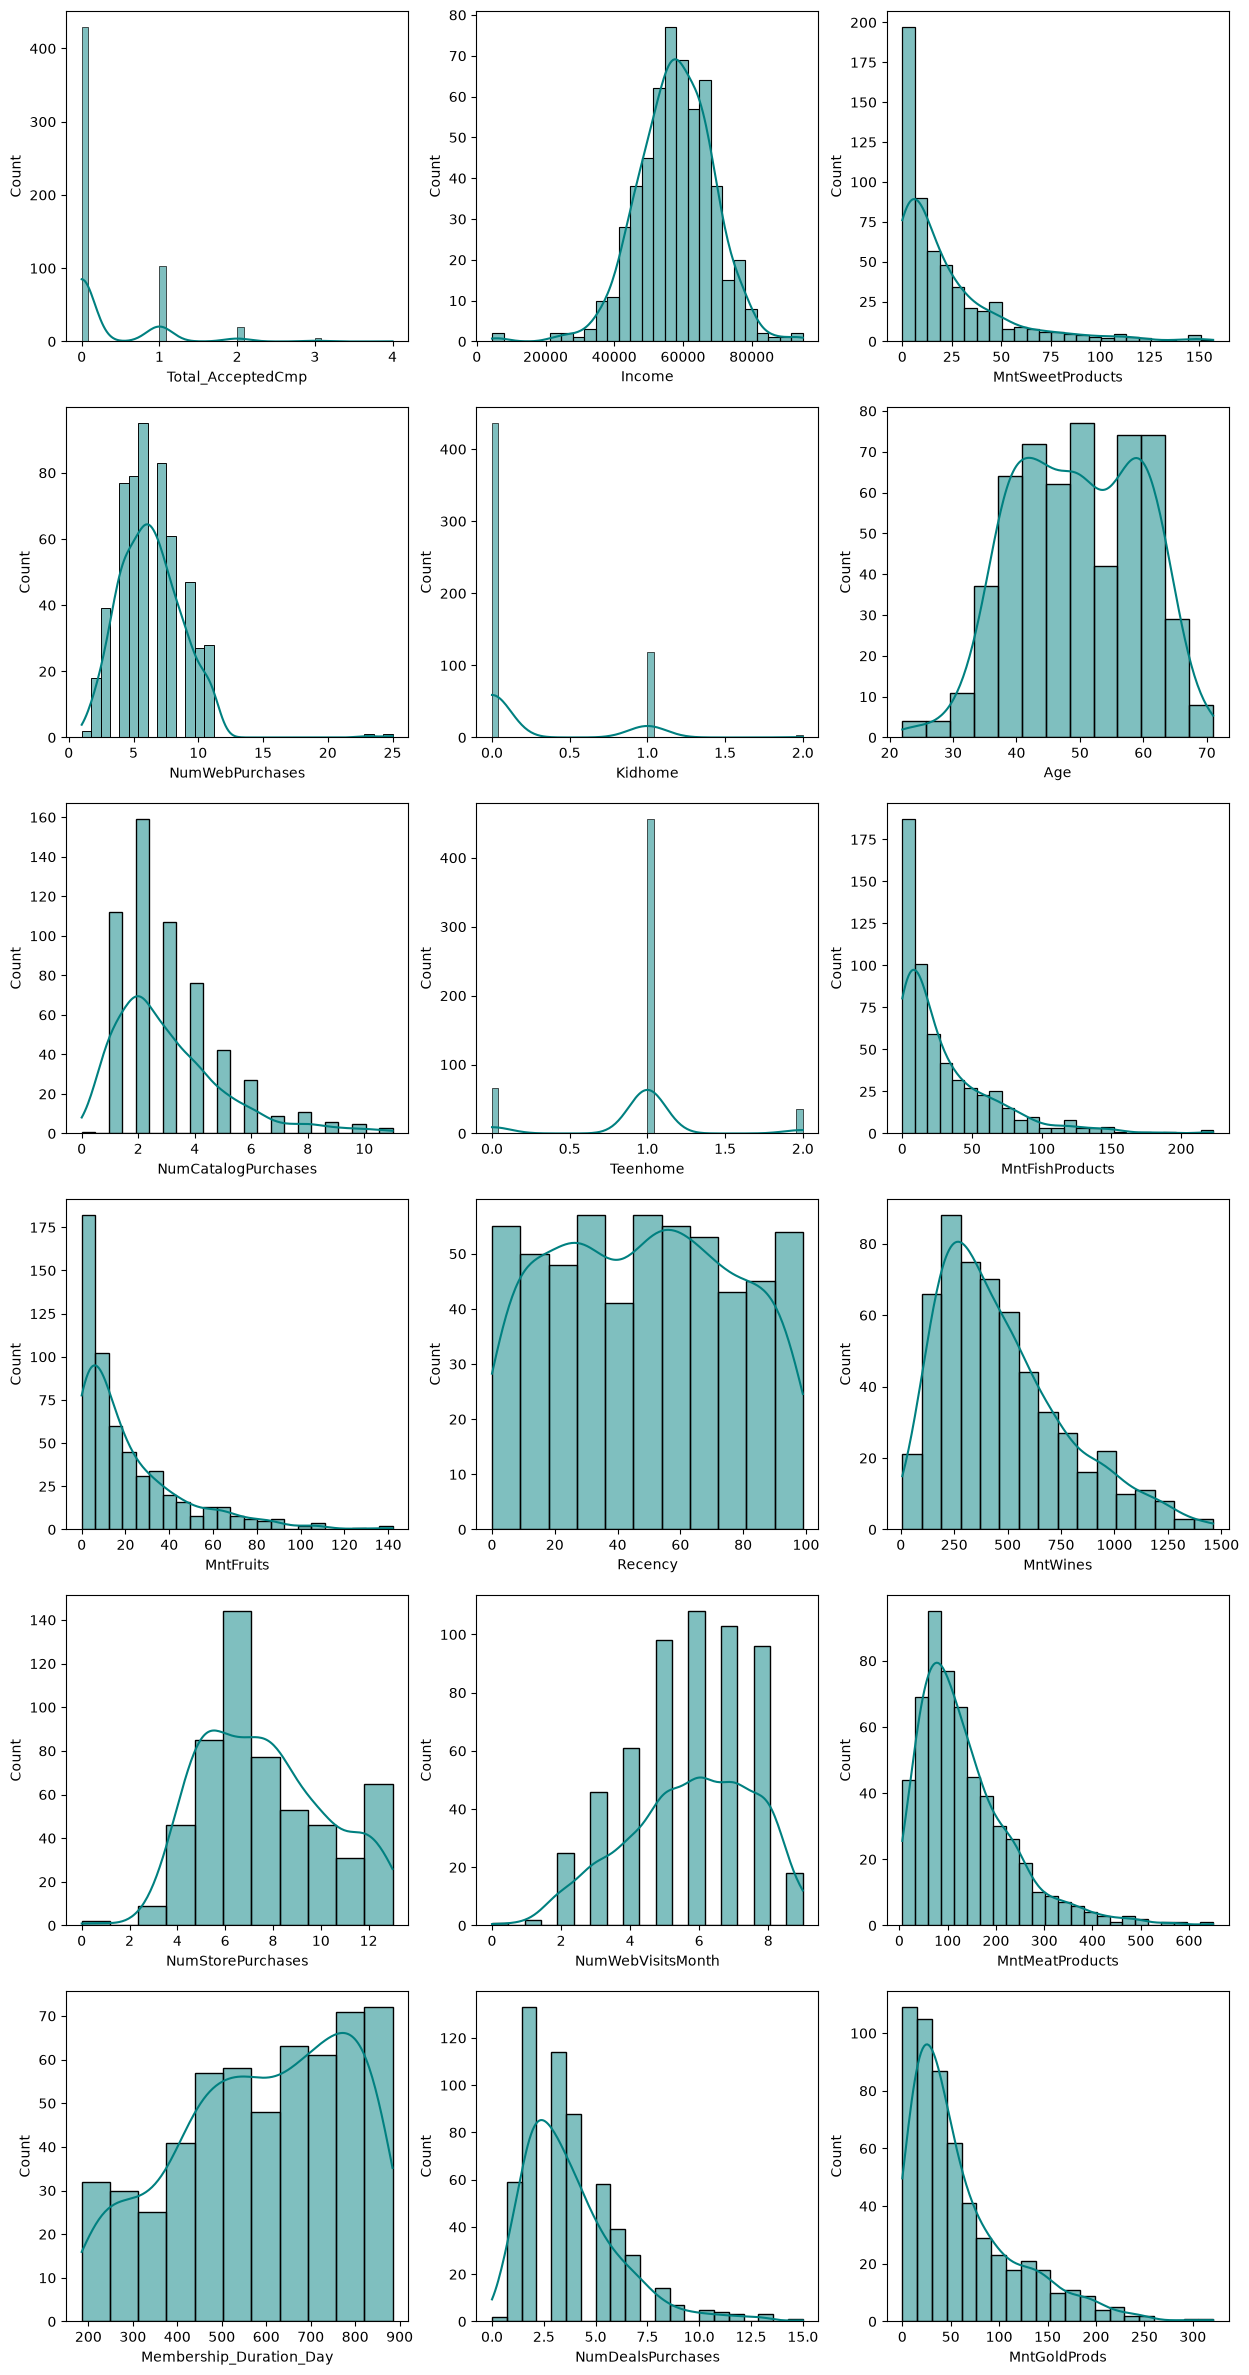

In [56]:
hist_plot_class(class_0_df, num_columns, target)

- **Demographics & Income**: Consists of mature individuals (aged 35–65) with high education levels (primarily Bachelor's/Graduation degrees, followed by PhDs and Master's). They belong to the middle-to-upper income bracket ($\$50,000 - \$65,000$) and are mostly married or living with a partner.

- **Household Structure**: Typically have no young children (Kidhome = 0) but have one teenager living at home (Teenhome = 1).

- **Spending & Behavior**: Their highest expenditures are concentrated in Wines ($\$200 - \$500$) and Meat Products ($\$50 - \$150$). They prefer shopping through physical stores (5–9 purchases) and websites (5–7 purchases). Furthermore, they represent long-term, loyal customers with a membership tenure exceeding 1.5 years (500–900 days).

- **Engagement & Satisfaction**: They rarely respond to specialized marketing campaigns (Total_AcceptedCmp is predominantly 0), although they occasionally utilize standard discount deals (2–4 purchases). They exhibit a near-zero complaint rate, indicating high satisfaction with baseline offerings.

### Class 1

In [40]:
class_1_df = feat_eng_df[feat_eng_df['label'] == 1]
class_1_df.head()

,Age,Education,Marital_Status,Income,Kidhome,Teenhome,Membership_Duration_Day,Recency,MntWines,MntFruits,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Total_AcceptedCmp,label
1,60,Graduation,Single,46344.0,1,1,298,38,11,1,...,1,6,2,1,1,2,5,0,0,1
3,30,Graduation,Together,26646.0,1,0,324,26,11,4,...,3,5,2,2,0,4,6,0,0,1
4,33,PhD,Married,58293.0,1,0,346,94,173,43,...,27,15,5,5,3,6,5,0,0,1
7,29,PhD,Married,33454.0,1,0,602,32,76,10,...,1,23,2,4,0,4,8,0,0,1
8,40,PhD,Together,30351.0,1,0,573,19,14,0,...,3,2,1,3,0,2,9,0,0,1


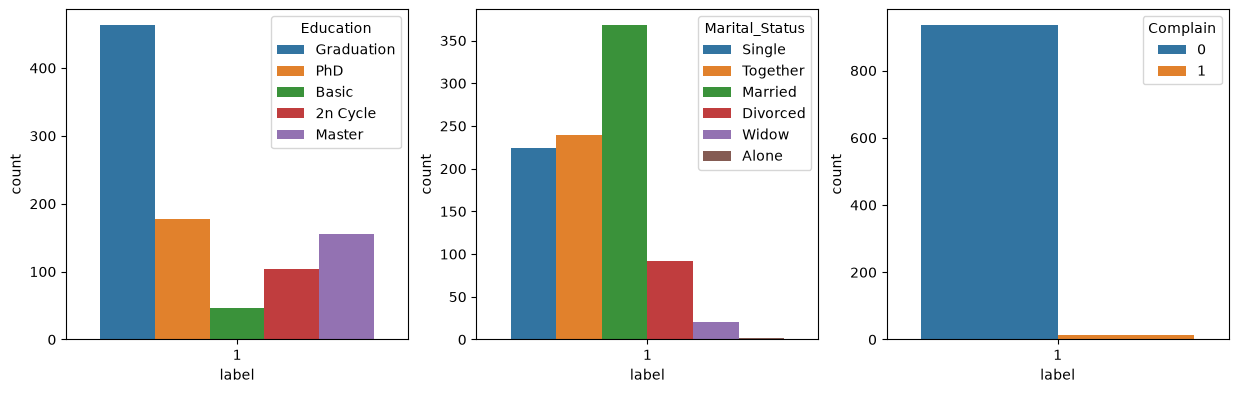

In [49]:
count_plot_class(class_1_df, cat_columns, target)

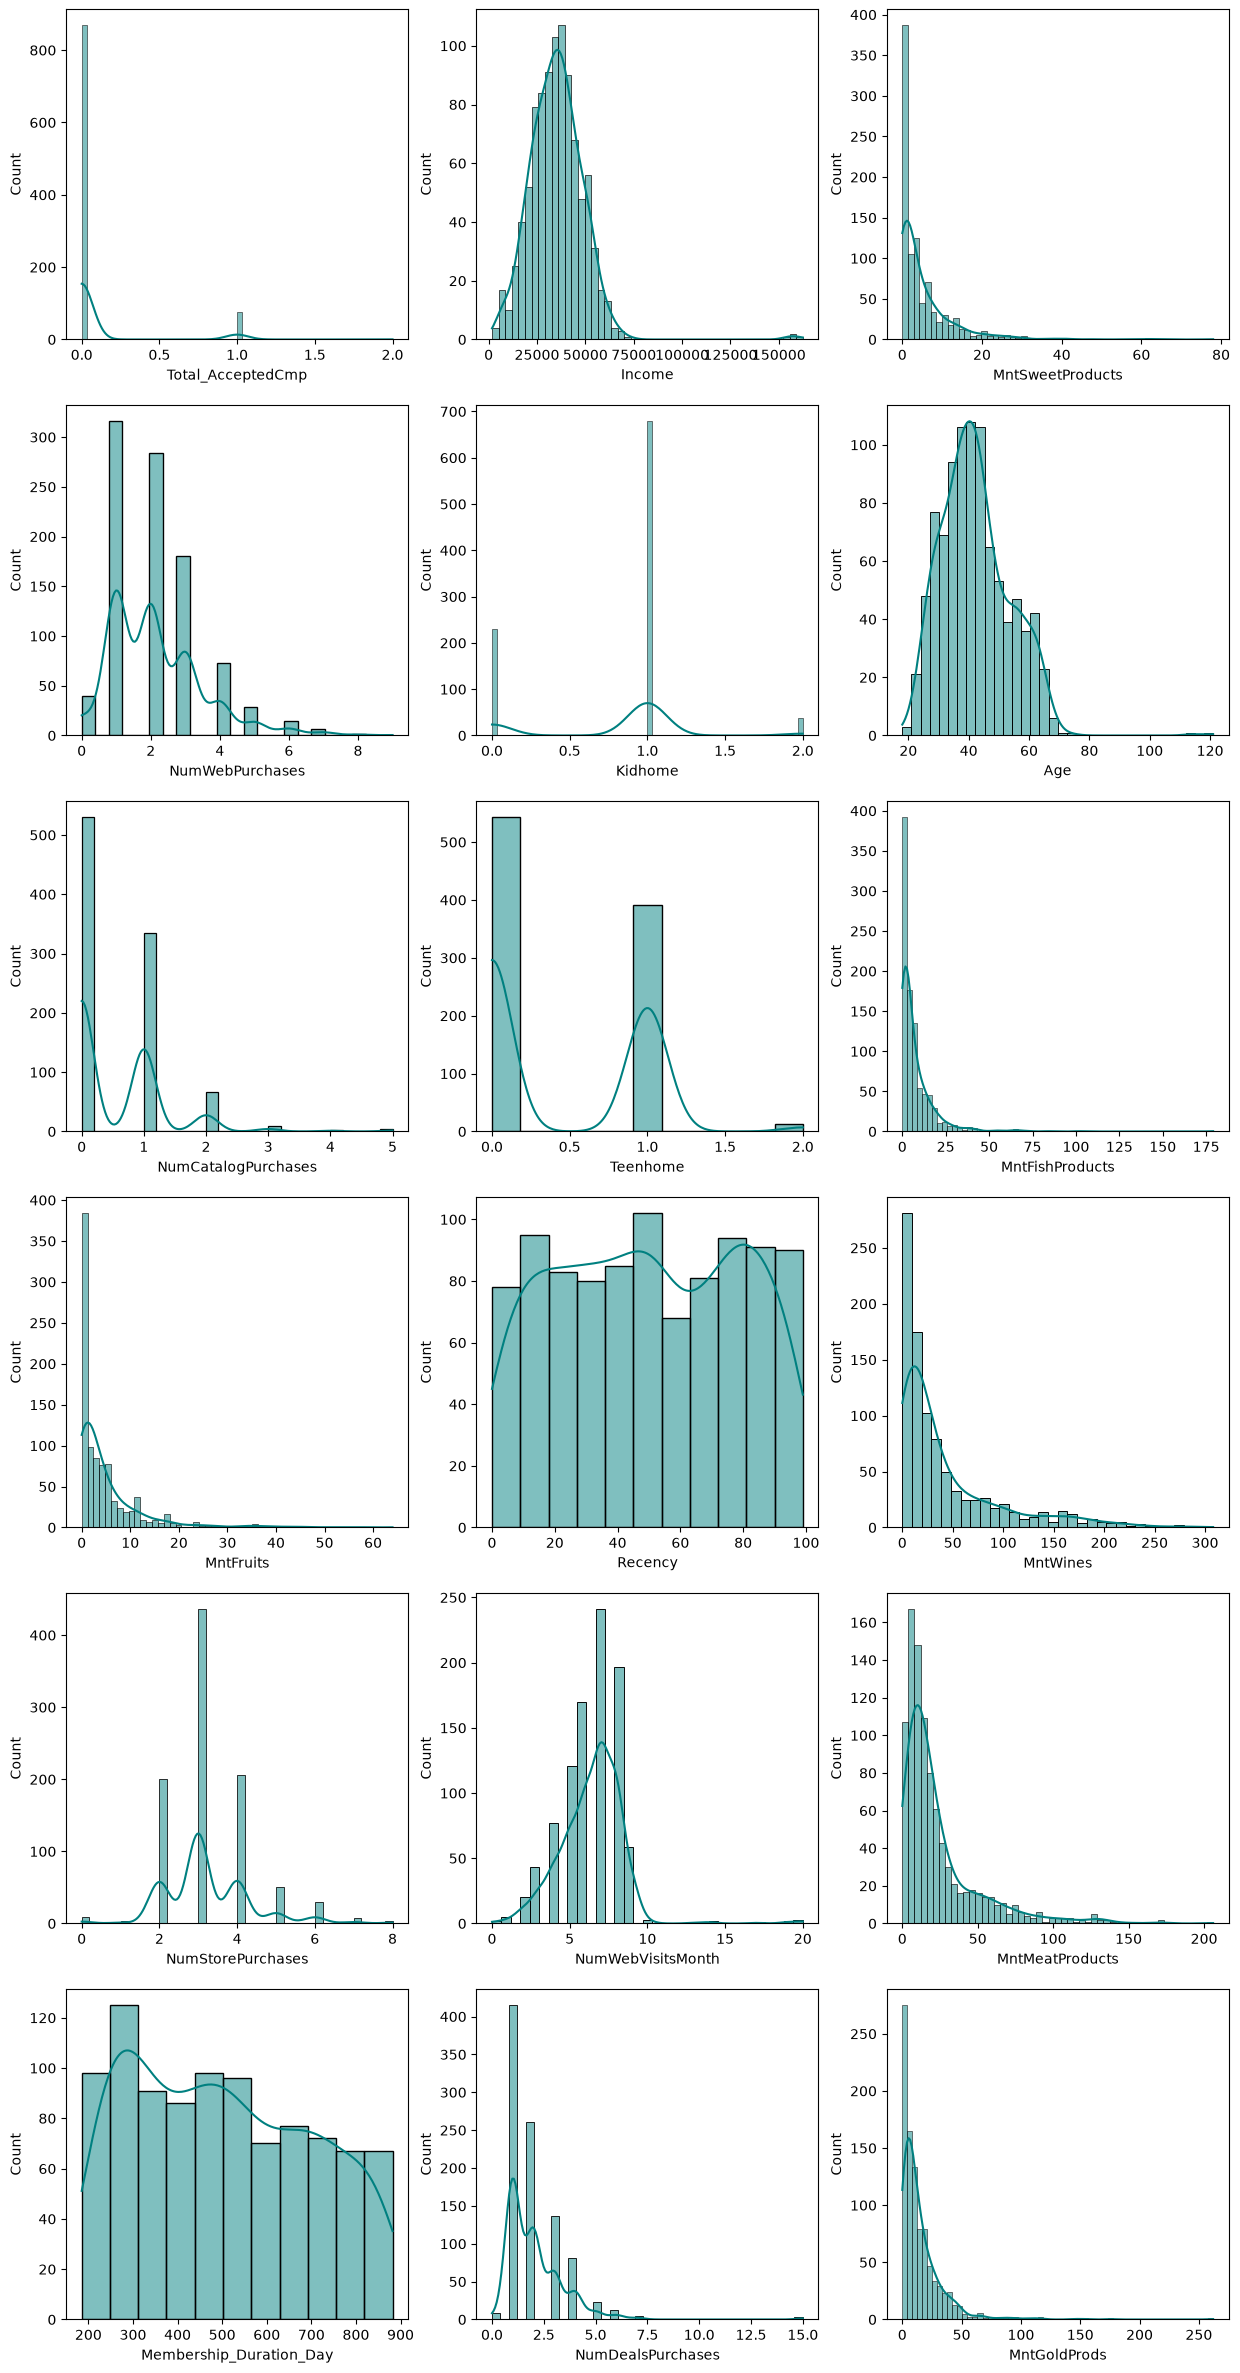

In [57]:
hist_plot_class(class_1_df, num_columns, target)

- **Demographics & Income**: Comprises a younger demographic (aged 30–45) in the lower-middle income segment ($\$25,000 - \$35,000$). Mostly hold bachelor degree.

- **Household Structure**: Characterized by a high presence of young children (Kidhome = 1) and occasionally teenagers.

- **Spending & Behavior**: Spending across all product categories (Wines, Meat, Sweets, Fish, Fruits, Gold) is exceptionally low, remaining close to zero. They exhibit high web traffic (6–8 monthly visits) but low conversion rates in actual web or store purchases (2–4 transactions), indicating a strong tendency toward online window shopping.

- **Engagement & Satisfaction**: They engage primarily with bargain deals (NumDealsPurchases) and show virtually zero acceptance of historical promotional campaigns (Total_AcceptedCmp = 0).

- **Business Strategy**: Best targeted with budget-friendly essential product bundles, direct discount vouchers, or free-shipping promotions to convert their high web visits into actual sales.

### Class 2

In [41]:
class_2_df = feat_eng_df[feat_eng_df['label'] == 2]
class_2_df.head()

,Age,Education,Marital_Status,Income,Kidhome,Teenhome,Membership_Duration_Day,Recency,MntWines,MntFruits,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Total_AcceptedCmp,label
0,57,Graduation,Single,58138.0,0,0,848,58,635,88,...,88,88,3,8,10,4,7,0,0,2
2,49,Graduation,Together,71613.0,0,0,497,26,426,49,...,21,42,1,8,2,10,4,0,0,2
12,55,Graduation,Divorced,63033.0,0,0,411,82,194,61,...,112,30,1,3,4,8,2,0,0,2
15,68,PhD,Single,82800.0,0,0,767,23,1006,22,...,68,45,1,7,6,12,3,0,2,2
21,35,Graduation,Married,2447.0,1,0,724,42,1,1,...,1,1,15,0,28,0,1,0,0,2


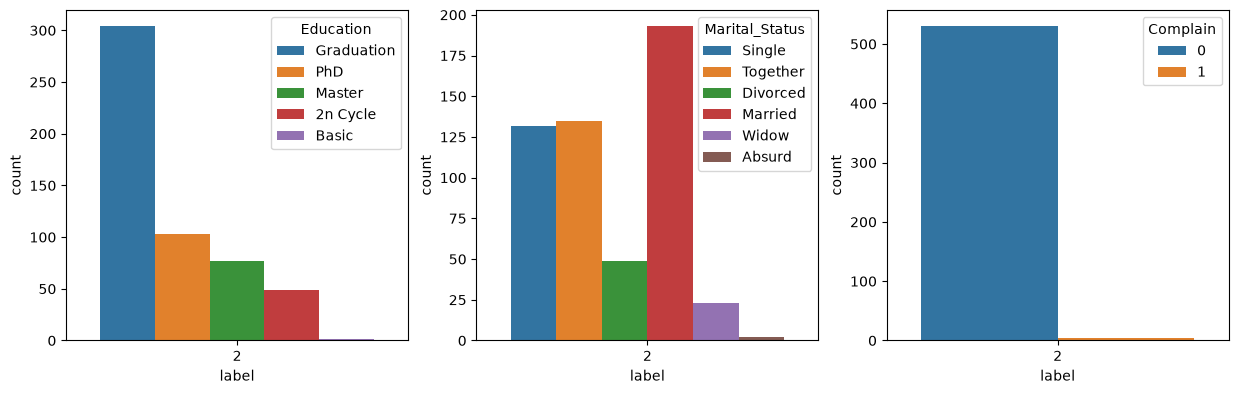

In [50]:
count_plot_class(class_2_df, cat_columns, target)

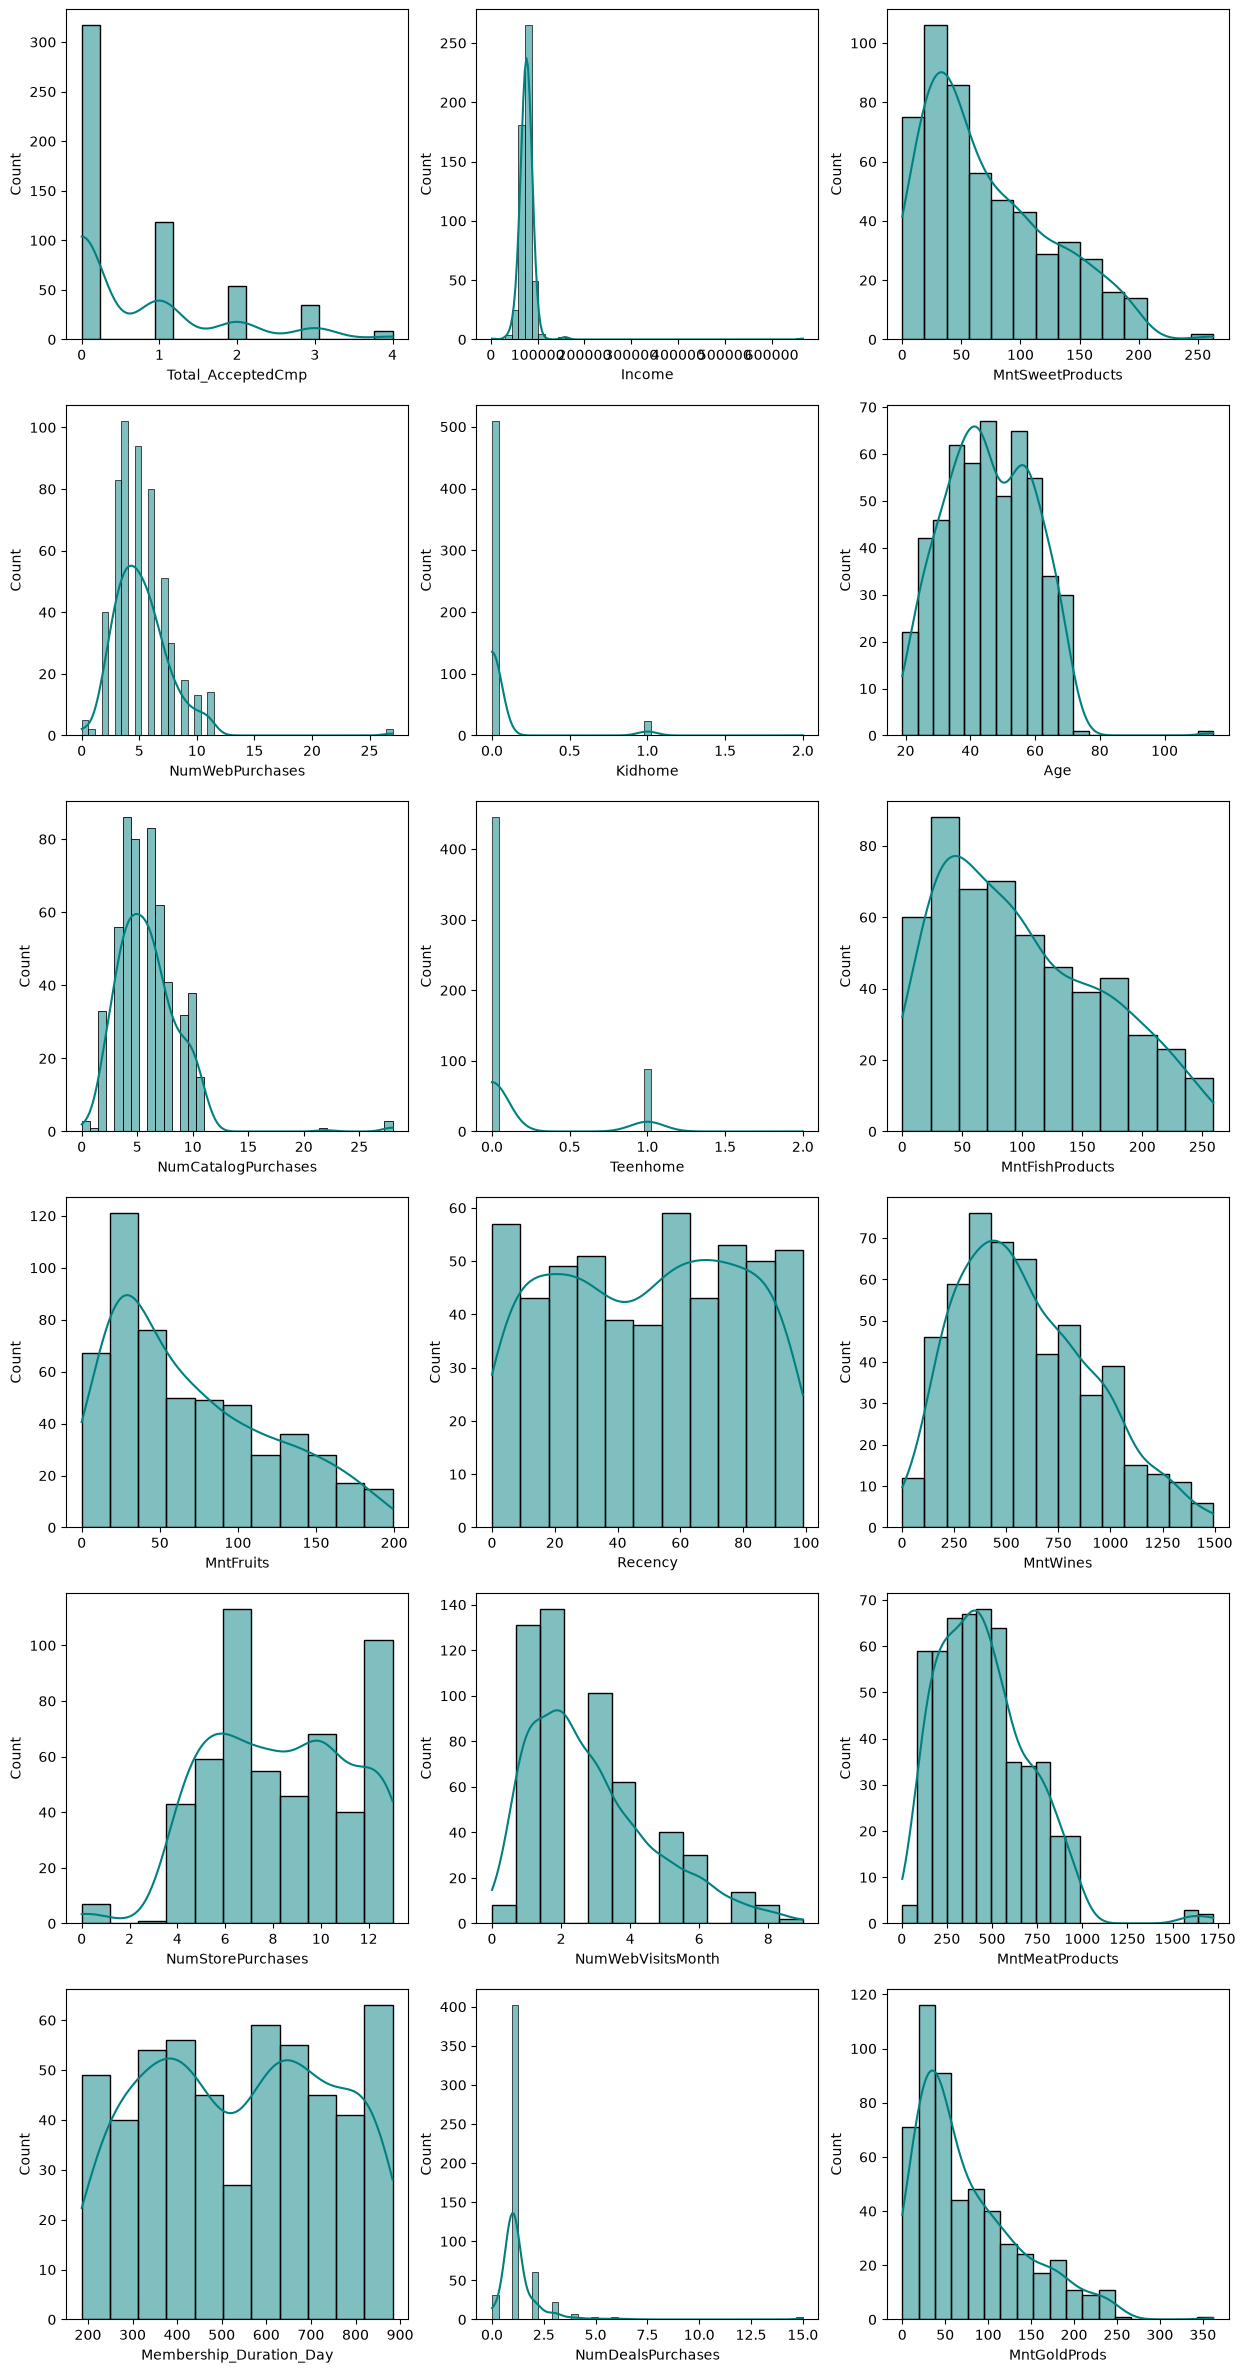

In [58]:
hist_plot_class(class_2_df, num_columns, target)

- **Demographics & Income**: Represents the highest-earning customer segment (high income: $\$75,000 - \$90,000+$), mostly mature adults (aged 35–60) with mostly bachelor degree backgrounds.

- **Household Structure**: Nearly zero dependents at home (both Kidhome and Teenhome are 0 for the vast majority of instances).

- **Spending & Behavior**: Demonstrates extremely high purchasing power across all categories, particularly Wines ($\$300 - \$1,000+$) and Meat Products ($\$200 - \$600+$). They favor in-store shopping (8–12 purchases) and catalog purchases (4–8 purchases). Notably, they record the lowest monthly web visits (1–4 visits) despite moderate-to-high web purchases, demonstrating high-intent purchasing rather than browsing.

- **Engagement & Satisfaction**: Highly responsive to marketing campaigns, with a significant portion accepting 1, 2, 3, or even 4 campaign offers (Total_AcceptedCmp). They show low sensitivity to discount deals (NumDealsPurchases is minimal) and maintain a zero complaint rate.

- **Business Strategy**: Ideal candidates for VIP loyalty programs, exclusive event invitations, catalog offerings, and premium limited-edition product promotions rather than mass discount campaigns.